In this notebook a *Naive* clustering of the dataset with **multi-hit ($\ge3$)** per event is done. **Standard clustering** algorithm are used without a deep parameter search.
Two different Data Representation is used:
- Every Feature 
- PCA 

On both representation clustering algorithm are tested. 

# 0 - General Set-Up

In this section general set up is done: import, dataset loading and processing.

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN, KMeans, AgglomerativeClustering
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import silhouette_score, normalized_mutual_info_score, adjusted_rand_score
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA

import sys
from pathlib import Path

sys.path.append(str(Path("../../../src/utils").resolve()))
from dataset_balancing import balance_dataset

To ensure corretct reproduction: 

In [2]:
random_state = 42
np.random.seed(random_state)

In [3]:
file_path = "../../../data/Engineered_Datasets/"
file_name = "bgtgf_ge3hit_dataset.csv"

ds = pd.read_csv(file_path + file_name, header=0)
print(f"Dataset shape perfore balancing: {ds.shape}")

print(ds['particle_type'].value_counts())

Dataset shape perfore balancing: (224816, 44)
particle_type
TGF                         141183
SecondaryPositrons           17141
PrimaryPositrons             14546
PrimaryProtons               12455
AlbedoPhotons                 8789
PrimaryAlphas                 7215
PrimaryElectrons              6464
SecondaryProtonsUpward        4594
SecondaryProtonsDownward      4256
SecondaryElectrons            4205
AtmosphericNeutrons           2043
CosmicPhotons                 1925
Name: count, dtype: int64


Sampling to balance the number of samples in the dataset:

In [ ]:
n_samples = 1000
ds = balance_dataset(ds, target_col="particle_type", n_samples = n_samples, random_state=random_state)
print(f"Dataset shape after balancing: {ds.shape}")

Dataset shape after balancing: (12000, 44)


In [5]:
X = ds.drop(columns=["particle_type", "pixel_ijk"])
y = ds["particle_type"]
print(f"X shape: {X.shape}, y shape: {y.shape}")

X shape: (12000, 42), y shape: (12000,)


# 1 - Data Representation

In this section we handle the data representation for the clustering algorithm:
- **Every feature** is kept ad pre-processing is done (log scaling and power transforming (Yeo-Johnons)).
- **PCA** with (90% variance) in order to keep only essential features and make the computation lighter and more efficient.

## 1.1 - Every Feature + Pre-Processing

Apply the power-transforming (Yeo-Jhonson) to rescale to unit variance and mean 0:

In [6]:
pt = PowerTransformer(standardize=True)
X_transformed = pt.fit_transform(X)
print(f"Dataset shape after power-transforming: {X_transformed.shape}")

pd.DataFrame(X_transformed, columns=X.columns).describe(include="all")

Dataset shape after power-transforming: (12000, 42)


,E_sum,E_mean,E_std,E_min,E_max,E_median,E_p10,E_p25,E_p75,E_p90,...,asym_z,span_x,span_y,span_z,hits_sum,D_f,L_max_hops,L_max_metric,N_b,L_skel
count,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,12000.000000,1.200000e+04,1.200000e+04,...,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,12000.000000,1.200000e+04,12000.000000,1.200000e+04
mean,7.200166e-16,-1.657933e-16,-1.468455e-16,-4.926430e-16,3.505344e-16,1.326346e-16,-1.667407e-15,0.000000,-4.736952e-16,2.842171e-17,...,-1.776357e-18,-1.136868e-16,1.894781e-17,-2.084259e-16,1.117921e-15,-2.842171e-17,0.000000,-1.894781e-17,0.000000,-7.579123e-17
std,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042,1.000042e+00,1.000042e+00,...,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042e+00,1.000042,1.000042e+00,1.000042,1.000042e+00
min,-2.444346e+00,-2.136227e+00,-2.531804e+00,-5.654399e+00,-2.515612e+00,-2.999839e+00,-4.252910e+00,-3.896724,-2.220795e+00,-2.127821e+00,...,-1.947898e+00,-1.955223e+00,-1.948543e+00,-1.978030e+00,-1.215099e+00,-1.806558e+00,-2.123185,-2.153357e+00,-0.851774,-4.038458e+00
25%,-6.324129e-01,-7.019862e-01,-5.472726e-01,-7.283733e-01,-5.120507e-01,-7.575926e-01,-6.825371e-01,-0.615688,-7.481956e-01,-6.534728e-01,...,-6.795754e-01,-5.732189e-01,-5.783086e-01,-5.960122e-01,-1.215099e+00,-6.333608e-01,-0.695029,-5.772736e-01,-0.851774,-6.938096e-01
50%,5.548543e-02,8.683022e-02,-7.833456e-03,-6.008030e-02,-6.480936e-03,-1.171849e-01,-1.265436e-01,-0.219962,1.178610e-01,7.763073e-02,...,5.598783e-02,-1.328524e-01,-1.389836e-01,-1.532656e-01,5.165238e-03,-3.621685e-03,0.008493,-9.191260e-02,-0.851774,-2.615796e-02
75%,6.192349e-01,7.333230e-01,7.166189e-01,6.807940e-01,6.156268e-01,8.662075e-01,8.092714e-01,0.874989,6.345439e-01,6.742008e-01,...,6.563172e-01,8.360306e-01,8.314708e-01,8.242393e-01,7.524893e-01,7.582547e-01,0.777594,6.330454e-01,1.024925,6.081690e-01
max,3.177504e+00,3.897737e+00,3.384034e+00,2.217401e+00,3.208574e+00,2.207283e+00,2.160153e+00,2.168733,3.647253e+00,4.383181e+00,...,1.981556e+00,1.540451e+00,1.540014e+00,1.537539e+00,1.997751e+00,2.844956e+00,2.295992,2.257634e+00,1.826788,2.393095e+00


## 1.2 - Principal Component Analisys

PCA is based on variance of features, so we feed the PCA algorithm with the 1.1 data which are scaled. We select the PC with variance >= 0.9

In [7]:
variance_threshold = 0.90

pca = PCA(n_components=variance_threshold, random_state=random_state)
X_pca = pd.DataFrame(pca.fit_transform(X_transformed), columns=[f"PC{i+1}" for i in range(pca.n_components_)])

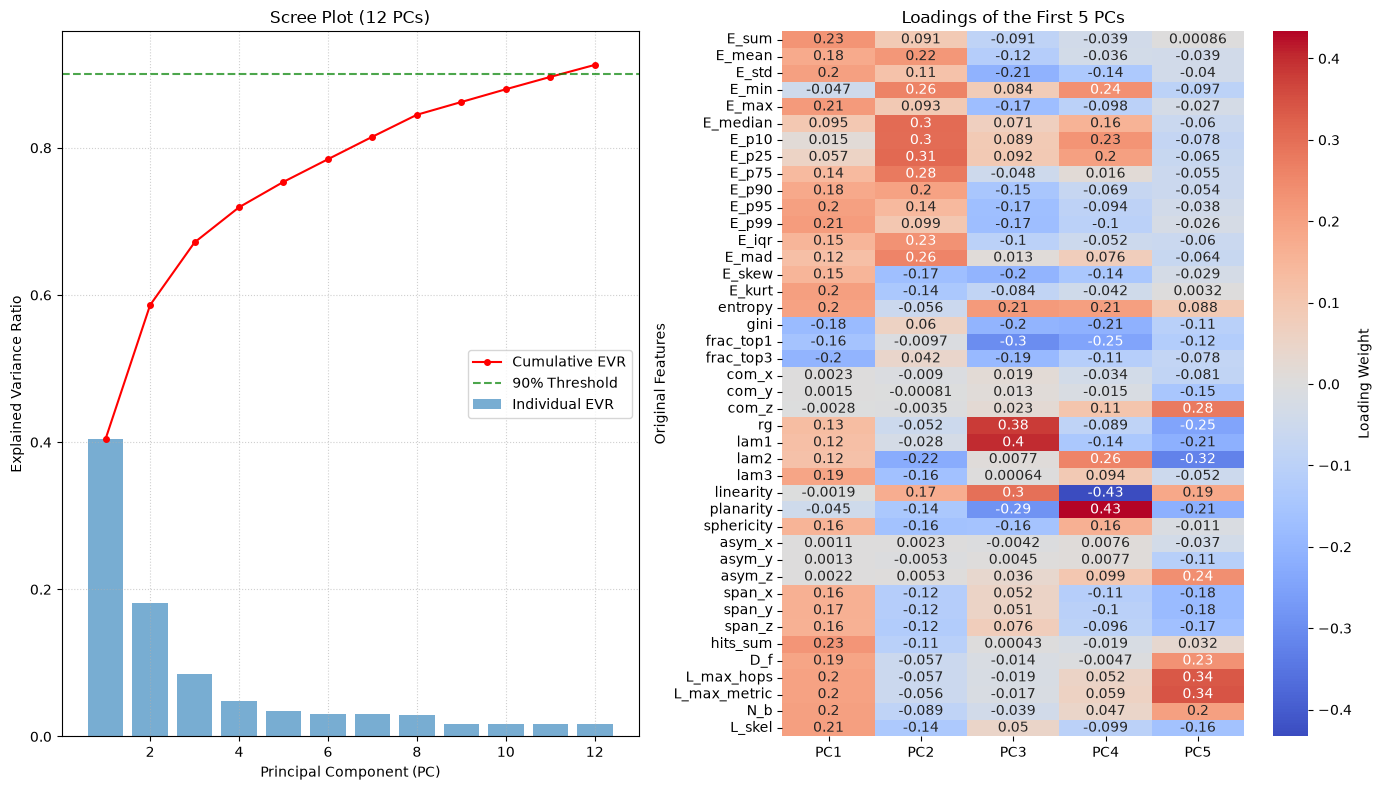

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# 1. Scree Plot
evr = pca.explained_variance_ratio_
pc_range = range(1, len(evr) + 1)

axes[0].bar(pc_range, evr, alpha=0.6, label="Individual EVR")
axes[0].plot(pc_range, np.cumsum(evr), "r-o", ms=4, label="Cumulative EVR")
axes[0].axhline(0.90, color="green", linestyle="--", alpha=0.7, label="90% Threshold")
axes[0].set_xlabel("Principal Component (PC)")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].set_title(f"Scree Plot ({pca.n_components_} PCs)")
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(loc="best")

# 2. Loadings dataframe
pc_names = [f"PC{i}" for i in range(1, pca.n_components_ + 1)]

if hasattr(pca, "feature_names_in_") and pca.feature_names_in_ is not None:
    feature_names = pca.feature_names_in_
else:
    feature_names = X.columns  

load = pd.DataFrame(
    pca.components_.T, 
    index=feature_names, 
    columns=pc_names
)

# Heatmap of 5 PCs loadings
n_pc_plot = min(5, pca.n_components_)
plt.sca(axes[1])
sns.heatmap(
    load.iloc[:, :n_pc_plot], 
    cmap="coolwarm", 
    center=0, 
    annot=True,  
    cbar_kws={"label": "Loading Weight"},
    ax=axes[1]
)
axes[1].set_title(f"Loadings of the First {n_pc_plot} PCs")
axes[1].set_ylabel("Original Features")

plt.tight_layout()
plt.show()

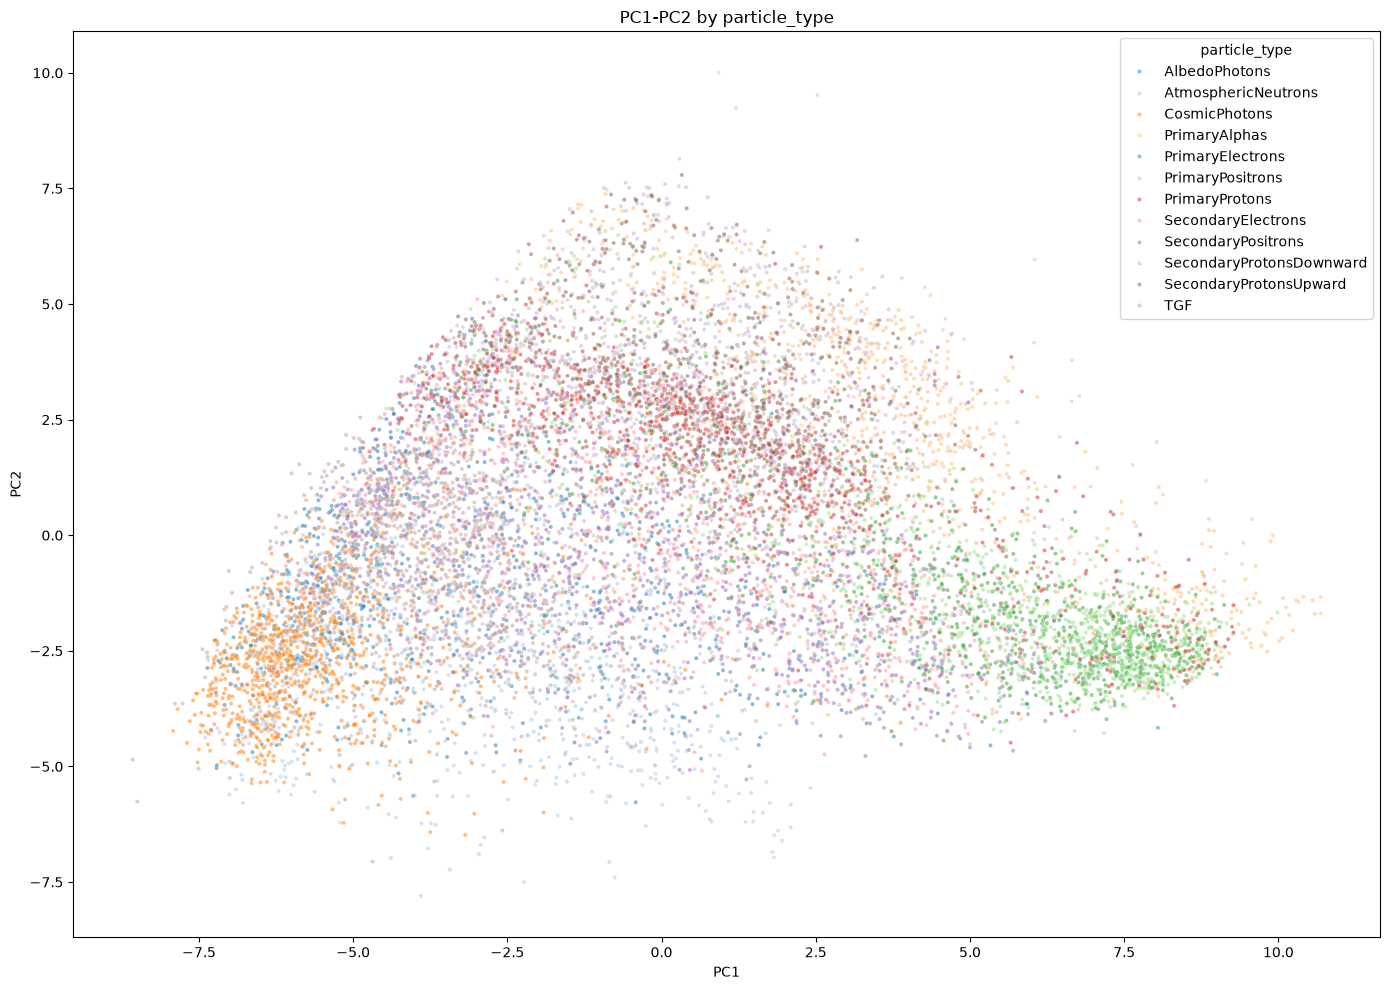

In [9]:
fig, axes = plt.subplots(1, 1, figsize=(14, 10))
sns.scatterplot(
    x=X_pca["PC1"], 
    y=X_pca["PC2"], 
    hue=y, 
    s=9, 
    alpha=0.5, 
    ax=axes, 
    palette="tab20"
)
axes.set_title("PC1-PC2 by particle_type"); 
#axes.legend(fontsize=6, markerscale=1.5, bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

# 2 - Clustering

In this section three clustering algorithm are tested on every data representation. The algorithms are:
- Kmean 
- Agglomerative Clustering
- DBSCAN

## 2.1 - KMeans

In [10]:
k_range = range(2, 13)
params = {
    "n_clusters": [*k_range],
    # "init": ["k-means++", "random"],
    #n_init": [10, 20, 30],
    #"max_iter": [300, 500, 1000],
}
pg = list(ParameterGrid(params))

In [11]:
def plot_sil_inertia(df):
    fig, ax1 = plt.subplots()

    color = "red"
    ax1.set_xlabel("Number of clusters")
    ax1.set_ylabel("Inertia", color=color)
    ax1.plot(k_range, df["inertia"], color=color)
    ax1.tick_params(axis="y", labelcolor=color)
    ax2 = ax1.twinx()

    color = "blue"
    ax2.set_xlabel("Number of clusters")
    ax2.set_ylabel("Silhouette", color=color)
    ax2.plot(k_range, df["silhouette"], color=color)
    ax2.tick_params(axis="y", labelcolor=color)
    ax2.set_ylim(0,1)

    fig.tight_layout()
    plt.show()

### Full Data representation

    n_clusters        inertia  silhouette       NMI       ARI
0          2.0  360852.229863    0.242107  0.150643  0.065551
1          3.0  290834.483408    0.230876  0.279022  0.144161
2          4.0  266285.671057    0.195266  0.283200  0.154901
3          5.0  246782.077043    0.193283  0.272347  0.152823
4          6.0  233153.649093    0.172797  0.300190  0.177825
5          7.0  226838.923642    0.156114  0.294511  0.165535
6          8.0  219885.608416    0.131231  0.300912  0.162584
7          9.0  214732.765768    0.125398  0.314165  0.179481
9         11.0  206293.367779    0.121509  0.314409  0.178152
8         10.0  210377.754605    0.119508  0.313468  0.181982
10        12.0  202114.230541    0.114799  0.319037  0.179358


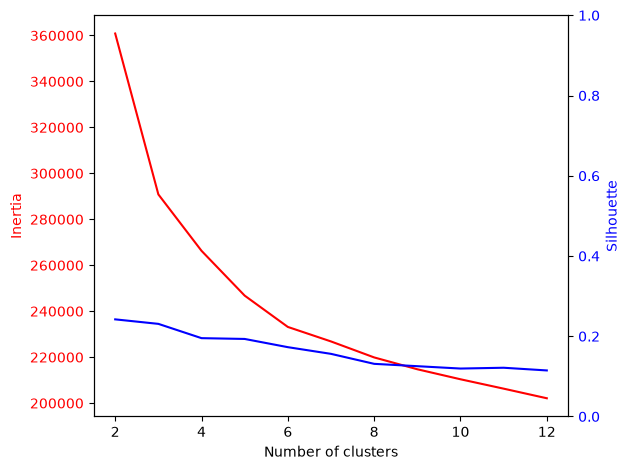

In [12]:
full_km_df = pd.DataFrame(columns=["n_clusters", "inertia",  "silhouette", "NMI", "ARI"])

for k in range(len(pg)):
    km = KMeans(**(pg[k]), random_state=random_state)
    ypred = km.fit_predict(X_transformed)

    full_km_df.loc[len(full_km_df)]=[
        pg[k]["n_clusters"],
        km.inertia_,
        silhouette_score(X_transformed, ypred),
        normalized_mutual_info_score(y, ypred),
        adjusted_rand_score(y, ypred)
    ]

# full_km_df = full_km_df.sort_values(by="silhouette", ascending=False).reset_index(drop=True)
print(full_km_df.sort_values(by="silhouette", ascending=False).head(n=15))

plot_sil_inertia(full_km_df)

Using the elbow method: 

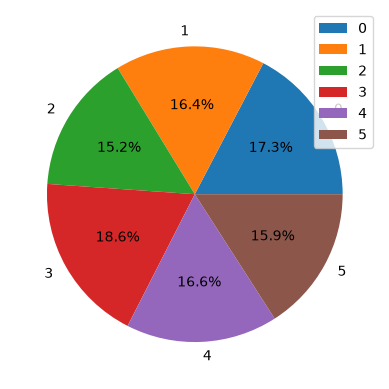

In [13]:
n_clusters = 6
km = KMeans(n_clusters=n_clusters, random_state=random_state)
y_full_km = km.fit_predict(X_transformed)

clust_size_full_km = np.unique(y_full_km,return_counts=True)
pd.DataFrame(clust_size_full_km[1]).plot.pie(y=0, autopct="%1.1f%%")
plt.show()

### PCA representation

    n_clusters        inertia  silhouette       NMI       ARI
0          2.0  316935.837739    0.263191  0.151222  0.065883
1          3.0  246990.084002    0.256277  0.278800  0.144129
3          5.0  203952.082029    0.217055  0.272071  0.152764
2          4.0  222821.248251    0.215364  0.264337  0.142259
4          6.0  190953.210893    0.195120  0.300290  0.177642
5          7.0  184687.979151    0.175246  0.296074  0.166503
6          8.0  178578.797460    0.154177  0.295251  0.166694
7          9.0  173248.229241    0.144499  0.313353  0.178769
9         11.0  164827.286633    0.141176  0.314263  0.176914
8         10.0  168595.942173    0.138921  0.317012  0.180185
10        12.0  162355.338765    0.136073  0.311395  0.174563


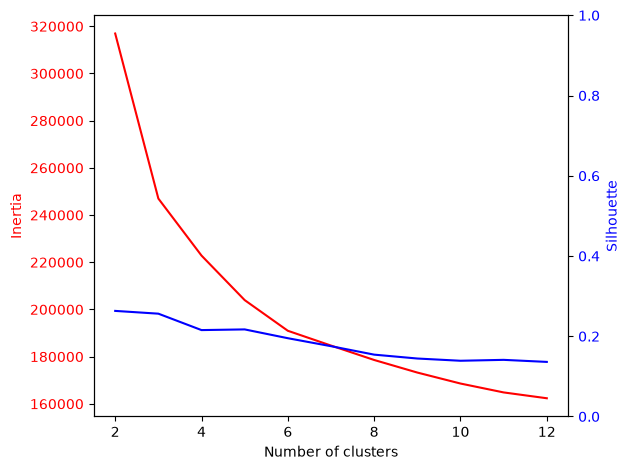

In [14]:
pca_km_df = pd.DataFrame(columns=["n_clusters", "inertia",  "silhouette", "NMI", "ARI"])

for k in range(len(pg)):
    km = KMeans(**(pg[k]), random_state=random_state)
    ypred = km.fit_predict(X_pca)

    pca_km_df.loc[len(pca_km_df)]=[
        pg[k]["n_clusters"],
        km.inertia_,
        silhouette_score(X_pca, ypred),
        normalized_mutual_info_score(y, ypred),
        adjusted_rand_score(y, ypred)
    ]

# full_km_df = full_km_df.sort_values(by="silhouette", ascending=False).reset_index(drop=True)
print(pca_km_df.sort_values(by="silhouette", ascending=False).head(n=15))

plot_sil_inertia(pca_km_df)

Using the elbow method: 

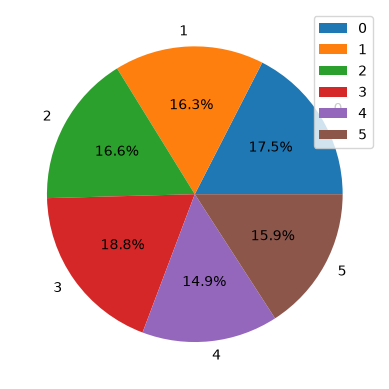

In [15]:
n_clusters = 6
km = KMeans(n_clusters=n_clusters, random_state=random_state)
y_pca_km = km.fit_predict(X_pca)

clust_size_pca_km = np.unique(y_pca_km,return_counts=True)
pd.DataFrame(clust_size_pca_km[1]).plot.pie(y=0, autopct="%1.1f%%")
plt.show()

## 2.2 - Agglomerative Clustering

In [16]:
k_range = range(10, 13)
parameters = [
    {
        "n_clusters": k_range,
        "linkage" : ["ward", "complete", "average", "single"]
    }
]
pg = list(ParameterGrid(parameters))

### Full Data representation

In [17]:
result_ac = []
for i in range(len(pg)):
    ac = AgglomerativeClustering(**(pg[i]))
    y_ac = ac.fit_predict(X_transformed)
    result_ac.append(
        [
            pg[i]["linkage"],
            pg[i]["n_clusters"],
            silhouette_score(X_transformed,y_ac),
            normalized_mutual_info_score(y, y_ac),
            adjusted_rand_score(y, y_ac)
        ]
    )

full_ac_df = pd.DataFrame(data = result_ac, columns=["linkage","n_clusters","silhouette_score","normalized_mutual_info_score","adjusted_rand_score"])
full_ac_df.sort_values(by="silhouette_score", ascending=False)

,linkage,n_clusters,silhouette_score,normalized_mutual_info_score,adjusted_rand_score
6,average,10,0.103590,0.266796,1.384937e-01
7,average,11,0.099908,0.266762,1.384923e-01
8,average,12,0.095780,0.280920,1.579623e-01
3,complete,10,0.088550,0.266345,1.451323e-01
4,complete,11,0.087082,0.267800,1.461221e-01
0,ward,10,0.075358,0.282890,1.515839e-01
1,ward,11,0.074134,0.287788,1.546829e-01
5,complete,12,0.073867,0.270004,1.463299e-01
2,ward,12,0.072788,0.297918,1.629254e-01
9,single,10,0.004690,0.001662,3.086548e-07


In [18]:
## Chose the best model based on silhouette score: take index of the table
index_best_model = full_ac_df["silhouette_score"].idxmax()
print(f"Best model index: {index_best_model} which corresponds to \n{full_ac_df.iloc[index_best_model]}")

ac = AgglomerativeClustering(**(pg[index_best_model]))
y_full_ac = ac.fit_predict(X_transformed)

Best model index: 6 which corresponds to 
linkage                          average
n_clusters                            10
silhouette_score                 0.10359
normalized_mutual_info_score    0.266796
adjusted_rand_score             0.138494
Name: 6, dtype: object


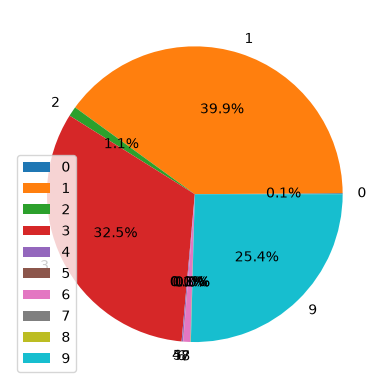

In [19]:
clust_sizes_full_ac = np.unique(y_full_ac,return_counts=True)
pd.DataFrame(clust_sizes_full_ac[1]).plot.pie(y=0, autopct='%1.1f%%', );
plt.show()

### PCA representation

In [20]:
result_ac = []
for i in range(len(pg)):
    ac = AgglomerativeClustering(**(pg[i]))
    y_ac = ac.fit_predict(X_pca)
    result_ac.append(
        [
            pg[i]["linkage"],
            pg[i]["n_clusters"],
            silhouette_score(X_pca,y_ac),
            normalized_mutual_info_score(y, y_ac),
            adjusted_rand_score(y, y_ac)
        ]
    )

pca_ac_df = pd.DataFrame(data = result_ac, columns=["linkage","n_clusters","silhouette_score","normalized_mutual_info_score","adjusted_rand_score"])
pca_ac_df.sort_values(by="silhouette_score", ascending=False)

,linkage,n_clusters,silhouette_score,normalized_mutual_info_score,adjusted_rand_score
7,average,11,0.127085,0.279527,1.517596e-01
6,average,10,0.126013,0.284671,1.500005e-01
8,average,12,0.119711,0.279686,1.517599e-01
3,complete,10,0.114544,0.265527,1.464315e-01
5,complete,12,0.111442,0.263360,1.475308e-01
4,complete,11,0.110717,0.266725,1.490513e-01
0,ward,10,0.089865,0.291569,1.602321e-01
1,ward,11,0.077261,0.303370,1.649108e-01
2,ward,12,0.076307,0.299944,1.593193e-01
9,single,10,-0.046885,0.001661,1.265608e-07


In [21]:
## Chose the best model based on silhouette score: take index of the table
index_best_model = pca_ac_df["silhouette_score"].idxmax()
print(f"Best model index: {index_best_model} which corresponds to \n{pca_ac_df.iloc[index_best_model]}")

ac = AgglomerativeClustering(**(pg[index_best_model]))
y_pca_ac = ac.fit_predict(X_pca)

Best model index: 7 which corresponds to 
linkage                          average
n_clusters                            11
silhouette_score                0.127085
normalized_mutual_info_score    0.279527
adjusted_rand_score              0.15176
Name: 7, dtype: object


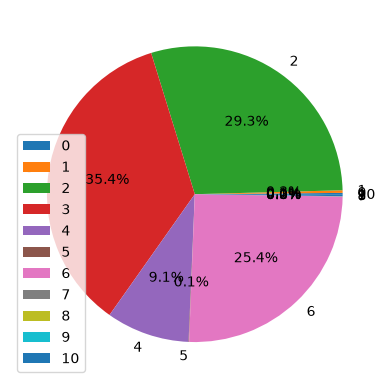

In [22]:
clust_sizes_pca_ac = np.unique(y_pca_ac,return_counts=True)
pd.DataFrame(clust_sizes_pca_ac[1]).plot.pie(y=0, autopct='%1.1f%%', );
plt.show()

## 2.3 - DBSCAN 

In [23]:
# param_grid = {
#     "eps":          list(np.arange(0.001, 1, 0.005)),
#     "min_samples":  list(range(2,10,1))
#     #"min_samples": [5, 10, 20]
# }
# params = list(ParameterGrid(param_grid))

In [24]:
# X_transformed = pd.DataFrame(X_transformed, columns=X.columns)

In [25]:
# from sklearn.neighbors import NearestNeighbors

# def kdist(X, k):
#     d, _ = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(np.asarray(X))
#     return np.sort(d[:, -1])

# # 1) k-distance plot: dove sta la scala di eps
# plt.figure(figsize=(7, 4))
# for name, Xr in {"full": X_transformed, "pca": X_pca}.items():
#     plt.plot(kdist(Xr, 20), label=name)
# plt.yscale("log"); plt.ylabel("20-NN distance"); plt.legend(); plt.show()

# # 2) griglia: eps dai quantili della k-distance
# def dbscan_grid(X, name, mss=(10, 20, 40), qs=(0.5, 0.6, 0.7, 0.8, 0.9, 0.95)):
#     rows, labs = [], {}
#     for ms in mss:
#         kd = kdist(X, ms)
#         for q in qs:
#             eps = float(np.quantile(kd, q))
#             lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(np.asarray(X))
#             m = lab != -1
#             sizes = pd.Series(lab[m]).value_counts()
#             ncl = len(sizes)
#             rows.append({"rep": name, "eps": eps, "min_samples": ms, "q": q,
#                          "n_clusters": ncl,
#                          "n_big": int((sizes >= 0.02 * len(lab)).sum()),   # cluster >= 2% dei punti
#                          "noise_%": 100 * (~m).mean(),
#                          "largest_%": 100 * sizes.max() / len(lab) if ncl else 0,
#                          "silhouette": silhouette_score(np.asarray(X)[m], lab[m], sample_size=5000, random_state=42) if ncl > 1 else np.nan,
#                          "NMI": normalized_mutual_info_score(y, lab),
#                          "ARI": adjusted_rand_score(y, lab)})
#             labs[(name, ms, q)] = lab
#     return pd.DataFrame(rows), labs

# db_full, labs_full = dbscan_grid(X_transformed, "full")
# db_pca, labs_pca = dbscan_grid(X_pca, "pca")
# pd.concat([db_full, db_pca]).round(3)

### Full Data representation

In [26]:
# full_db_df = pd.DataFrame(columns =  ['eps','min_samples','n_clusters', 'unclust%', 'silhouette', 'ARI', 'NMI'])

# for i in range(len(params)):
#     db = DBSCAN(**(params[i]))
#     y_db = db.fit_predict(X_transformed)

#     # count the number of clusters and the number of noise points
#     cluster_labels_all = np.unique(y_db)
#     cluster_labels = cluster_labels_all[cluster_labels_all != -1]
#     n_clusters = len(cluster_labels)

#     # Only compute silhouette score if there are at least 2 clusters and less than the number of samples
#     if 1 < n_clusters and n_clusters < len(y_db):

#         # Filter out noise points for silhouette score calculation
#         X_cl = X_transformed.loc[y_db!=-1,:]
#         y_db_cl = y_db[y_db!=-1]
#         silhouette = silhouette_score(X_cl,y_db_cl)
#         ARI = adjusted_rand_score(y, y_db)
#         NMI = normalized_mutual_info_score(y, y_db)

#         # Calculate the percentage of unclustered points
#         uncl_p = (1 - y_db_cl.shape[0]/y_db.shape[0]) * 100
#         full_db_df.loc[len(full_db_df)] = [
#             db.eps, 
#             db.min_samples,
#             n_clusters, 
#             uncl_p,
#             silhouette,
#             ARI,
#             NMI
#         ]

In [27]:
# full_db_df.head().sort_values(by="unclust%", ascending=True)

In [28]:
# sil_thr = 0.0   # visualize results only for combinations with silhouette above the threshold
# unc_thr = 20     # visualize results only for combinations with unclustered% below the threshold
# n_clu_max_thr = 5

# full_db_df[(full_db_df['silhouette']>=sil_thr)\
#          & (full_db_df['unclust%']<=unc_thr)\
#          & (full_db_df['n_clusters']<=n_clu_max_thr)].sort_values(['silhouette','unclust%'],ascending=[False,True])

In [29]:
# best = {'eps': 0.526, 'min_samples': 9}
# # db = DBSCAN(**(params[db_best_par]))
# db = DBSCAN(**best)
# y_full_db = db.fit_predict(X_transformed)

In [30]:
# clust_sizes_full_db = np.unique(y_full_db[y_full_db!=-1],return_counts=True)
# pd.DataFrame(clust_sizes_full_db[1]).plot.pie(y=0, autopct='%1.1f%%');
# plt.show()

### PCA representation

In [31]:
# pca_db_df = pd.DataFrame(columns =  ['eps','min_samples','n_clusters', 'unclust%', 'silhouette', 'ARI', 'NMI'])

# for i in range(len(params)):
#     db = DBSCAN(**(params[i]))
#     y_db = db.fit_predict(X_pca)

#     # count the number of clusters and the number of noise points
#     cluster_labels_all = np.unique(y_db)
#     cluster_labels = cluster_labels_all[cluster_labels_all != -1]
#     n_clusters = len(cluster_labels)

#     # Only compute silhouette score if there are at least 2 clusters and less than the number of samples
#     if 1 < n_clusters and n_clusters < len(y_db):

#         # Filter out noise points for silhouette score calculation
#         X_cl = X_pca.loc[y_db!=-1,:]
#         y_db_cl = y_db[y_db!=-1]
#         silhouette = silhouette_score(X_cl,y_db_cl)
#         ARI = adjusted_rand_score(y, y_db)
#         NMI = normalized_mutual_info_score(y, y_db)

#         # Calculate the percentage of unclustered points
#         uncl_p = (1 - y_db_cl.shape[0]/y_db.shape[0]) * 100
#         pca_db_df.loc[len(pca_db_df)] = [
#             db.eps, 
#             db.min_samples,
#             n_clusters, 
#             uncl_p,
#             silhouette,
#             ARI,
#             NMI
#         ]

In [32]:
# sil_thr = 0.2   # visualize results only for combinations with silhouette above the threshold
# unc_thr = 5     # visualize results only for combinations with unclustered% below the threshold
# n_clu_max_thr = 5

# pca_db_df[(pca_db_df['silhouette']>=sil_thr)\
#          & (pca_db_df['unclust%']<=unc_thr)\
#          & (pca_db_df['n_clusters']<=n_clu_max_thr)].sort_values(['silhouette','unclust%'],ascending=[False,True])

In [33]:
# best = {'eps': 0.526, 'min_samples': 9}
# # db = DBSCAN(**(params[db_best_par]))
# db = DBSCAN(**best)
# y_pca_db = db.fit_predict(X_pca)

In [34]:
# clust_sizes_pca_db = np.unique(y_pca_db[y_pca_db!=-1],return_counts=True)
# pd.DataFrame(clust_sizes_pca_db[1]).plot.pie(y=0, autopct='%1.1f%%');
# plt.show()

# 3 - Comparison and Results

In [35]:
models_dict = {
    "KMeans (Full, k=6)": (y_full_km, X_transformed),
    "KMeans (PCA, k=6)": (y_pca_km, X_pca),
    "Agglomerative (Full, k=10)": (y_full_ac, X_transformed),
    "Agglomerative (PCA, k=11)": (y_pca_ac, X_pca),
}

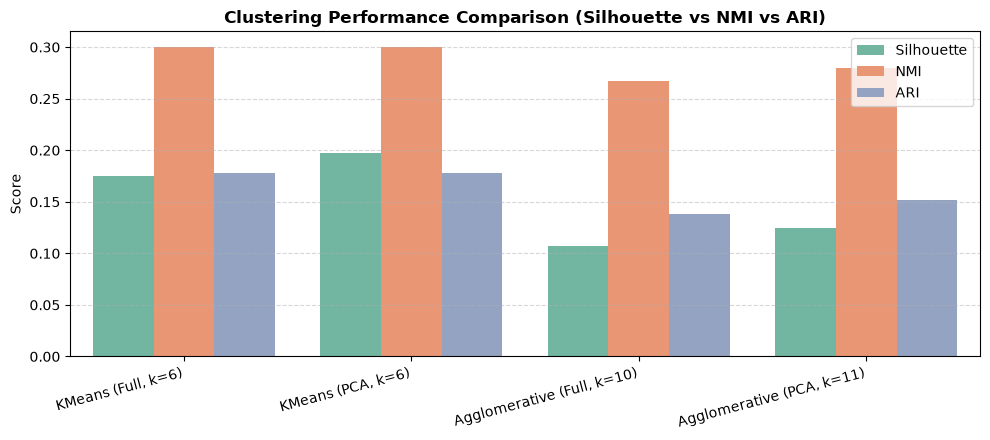

In [36]:
# METRICS COMPARISON BARPLOT
def plot_metrics_summary(models, y_true):
    """Computes and plots Silhouette, NMI, and ARI across all registered models."""
    records = []
    for name, (labels, data) in models.items():
        # Calculate scores
        sil = silhouette_score(data, labels, sample_size=5000, random_state=42)
        nmi = normalized_mutual_info_score(y_true, labels)
        ari = adjusted_rand_score(y_true, labels)

        records.append(
            {"Model": name, "Silhouette": sil, "NMI": nmi, "ARI": ari}
        )

    df_metrics = pd.DataFrame(records)

    # Plot grouped barplot
    df_melt = df_metrics.melt(
        id_vars="Model", var_name="Metric", value_name="Score"
    )
    plt.figure(figsize=(10, 4.5))
    ax = sns.barplot(
        data=df_melt, x="Model", y="Score", hue="Metric", palette="Set2"
    )
    plt.title(
        "Clustering Performance Comparison (Silhouette vs NMI vs ARI)",
        fontweight="bold",
        fontsize=12,
    )
    plt.ylabel("Score")
    plt.xlabel("")
    plt.xticks(rotation=15, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

    return df_metrics

df_summary = plot_metrics_summary(models_dict, y)


- All models have similar scores.
- PCA (12 components) performs like the full feature set (KMeans NMI 0.265 vs 0.266)
- Silhouette is very low: clusters overlap.

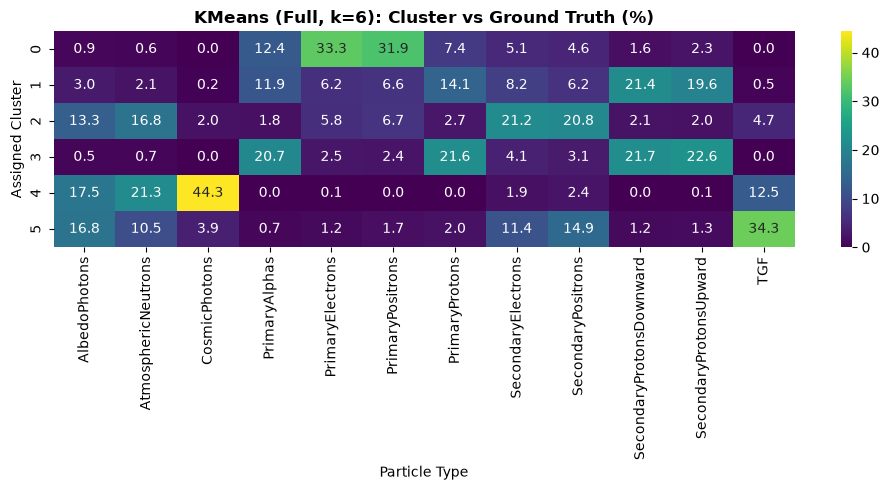

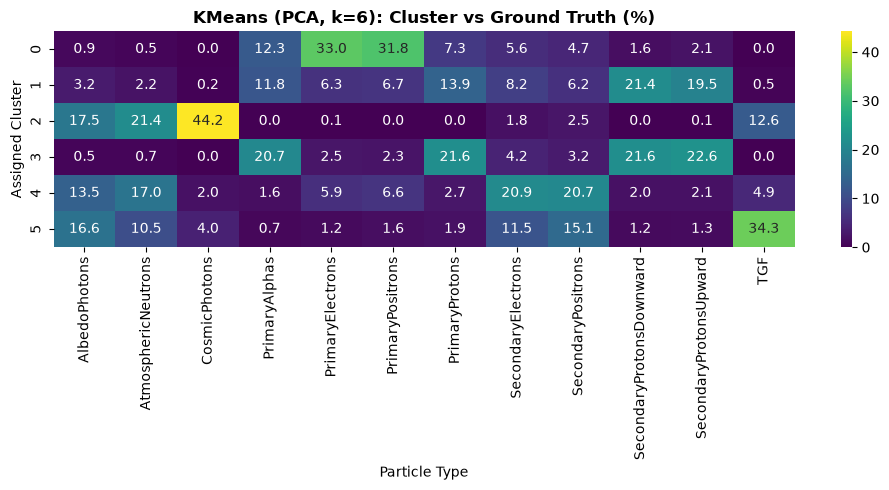

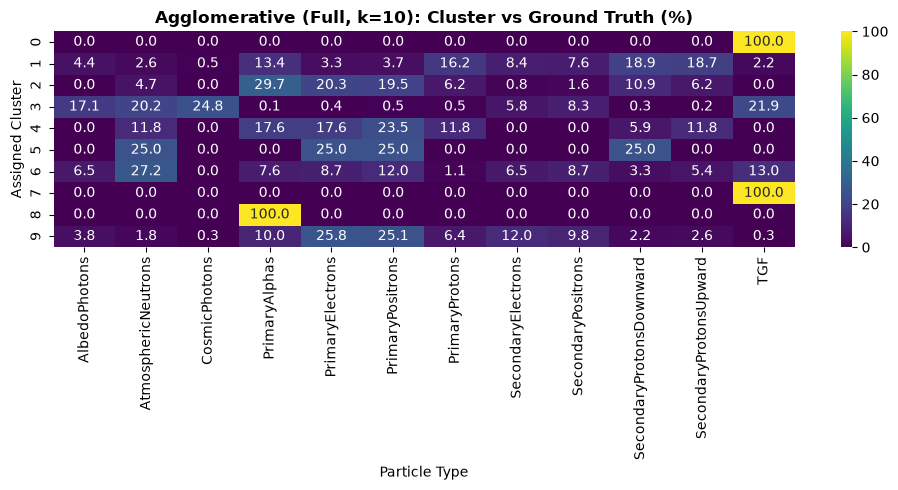

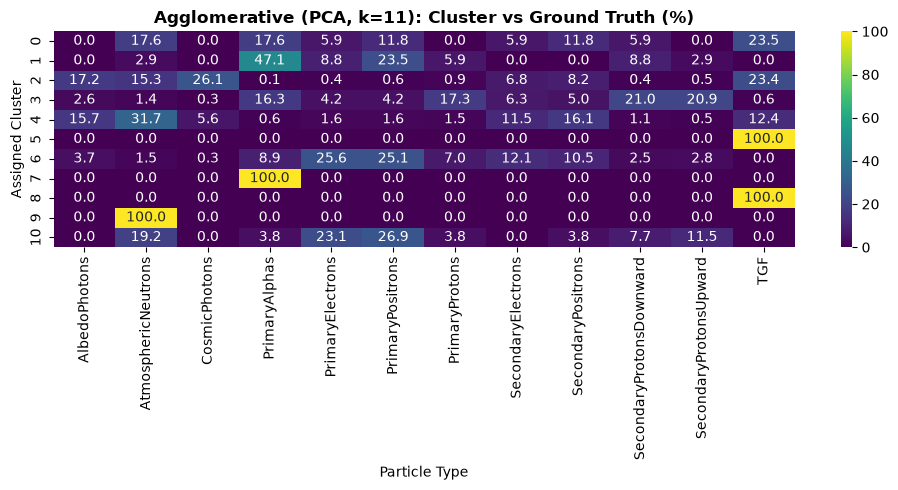

In [37]:
for name, (labels, data) in models_dict.items():
    # Safely convert data to DataFrame with column headers
    if isinstance(data, np.ndarray):
        col_names = (
            X.columns
            if data.shape[1] == X.shape[1]
            else [f"PC{i+1}" for i in range(data.shape[1])]
        )
        df_temp = pd.DataFrame(data, columns=col_names)
    else:
        df_temp = data.copy()

    df_temp["cluster"] = labels

    ct = (
        pd.crosstab(df_temp["cluster"], y, normalize="index") * 100
    )

    plt.figure(figsize=(10, 5))
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="viridis")
    plt.title(f"{name}: Cluster vs Ground Truth (%)", fontweight="bold")
    plt.xlabel("Particle Type")
    plt.ylabel("Assigned Cluster")
    plt.tight_layout()
    plt.show()

In [38]:
# for each algorithm show a table with the number of particles in each cluster
for name, (labels, data) in models_dict.items():
    # Safely convert data to DataFrame with column headers
    if isinstance(data, np.ndarray):
        col_names = (
            X.columns
            if data.shape[1] == X.shape[1]
            else [f"PC{i+1}" for i in range(data.shape[1])]
        )
        df_temp = pd.DataFrame(data, columns=col_names)
    else:
        df_temp = data.copy()

    df_temp["cluster"] = labels

    cluster_counts = df_temp["cluster"].value_counts().sort_index()
    print(f"\n{name} - Cluster Counts:")
    print(cluster_counts)



KMeans (Full, k=6) - Cluster Counts:
cluster
0    2080
1    1968
2    1819
3    2232
4    1991
5    1910
Name: count, dtype: int64

KMeans (PCA, k=6) - Cluster Counts:
cluster
0    2096
1    1961
2    1994
3    2259
4    1786
5    1904
Name: count, dtype: int64

Agglomerative (Full, k=10) - Cluster Counts:
cluster
0      13
1    4789
2     128
3    3899
4      17
5       4
6      92
7       4
8       3
9    3051
Name: count, dtype: int64

Agglomerative (PCA, k=11) - Cluster Counts:
cluster
0       17
1       34
2     3522
3     4253
4     1093
5        7
6     3043
7        3
8        1
9        1
10      26
Name: count, dtype: int64


In [39]:

# top_n_features = 6
# for name, (labels, data) in models_dict.items():
#     cols_to_plot = [c for c in df_temp.columns if c != "cluster"][
#         :top_n_features
#     ]
#     prof = df_temp.groupby("cluster")[cols_to_plot].mean()

#     plt.figure(figsize=(8, 3.5))
#     sns.heatmap(prof, annot=True, fmt=".2f", cmap="coolwarm", center=0)
#     plt.title(
#         f"{name}: Mean Profile (First {top_n_features} Features)",
#         fontweight="bold",
#     )
#     plt.xlabel("Feature / Principal Component")
#     plt.ylabel("Cluster")
#     plt.tight_layout()
#     plt.show()


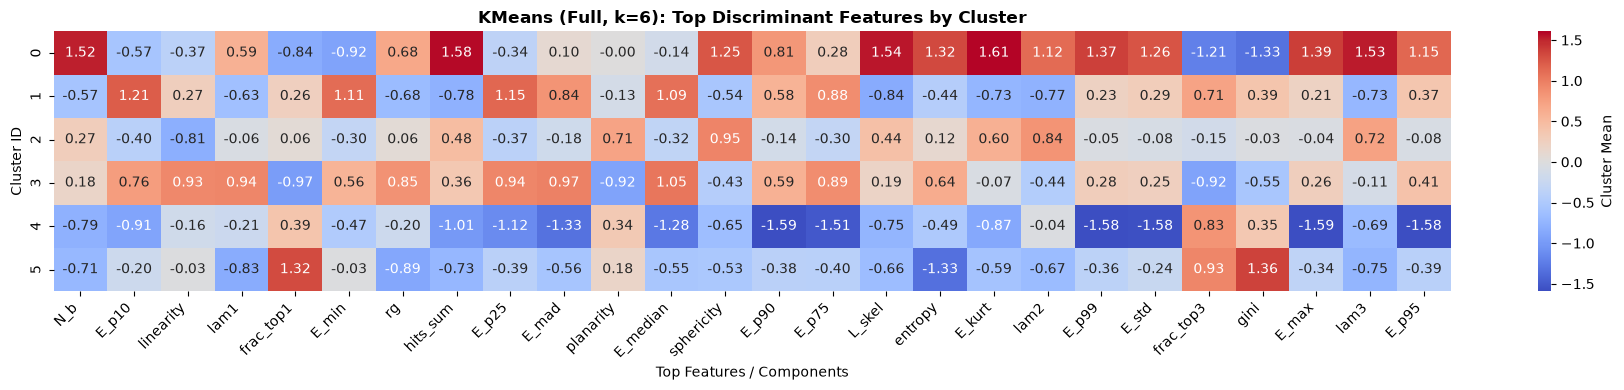

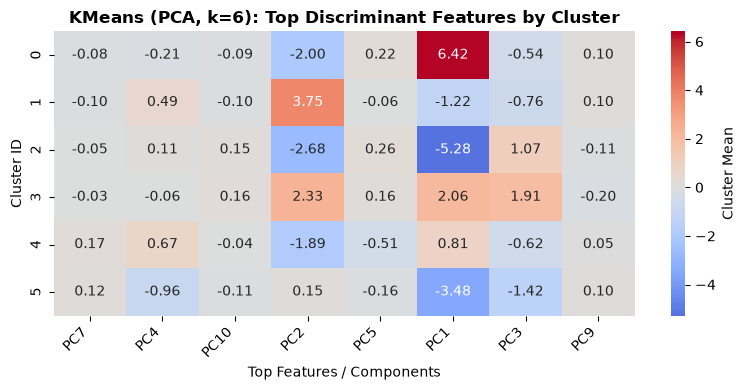

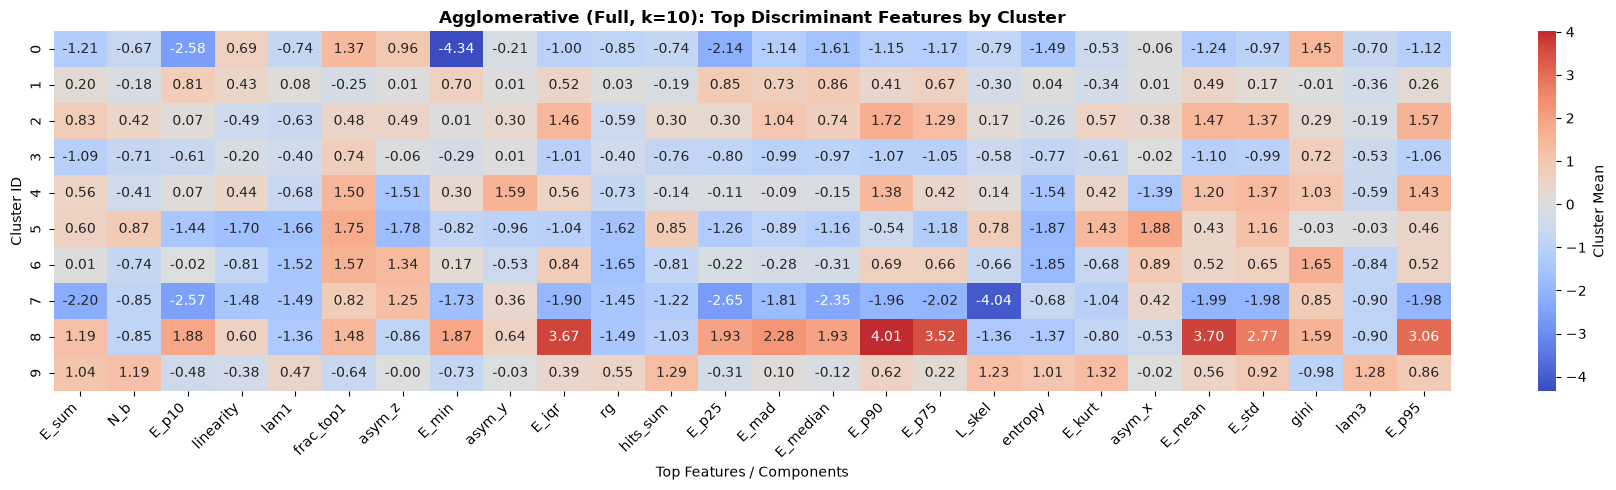

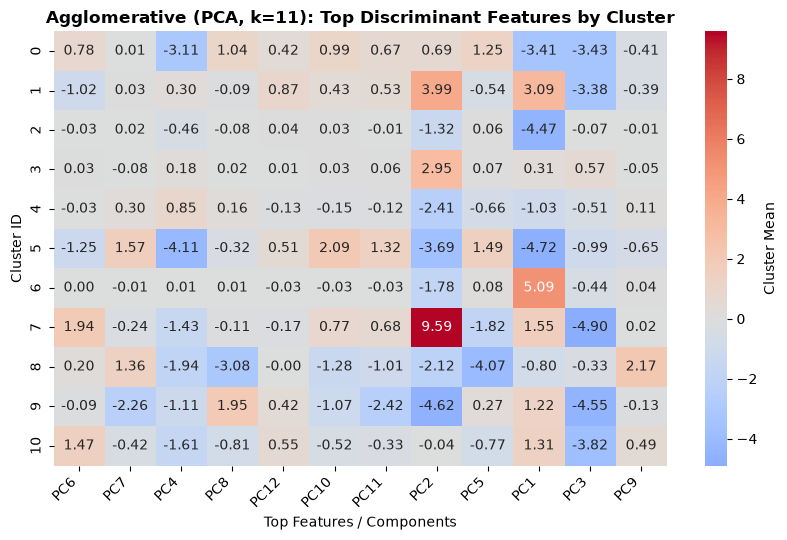

In [40]:
# This code filters and displays only the top discriminant features per cluster. 
top_n = 5
for name, (labels, data) in models_dict.items():
    if isinstance(data, np.ndarray):
        col_names = (
            X.columns
            if data.shape[1] == X.shape[1]
            else [f"PC{i+1}" for i in range(data.shape[1])]
        )
        df_temp = pd.DataFrame(data, columns=col_names)
    else:
        df_temp = data.copy()

    df_temp["cluster"] = labels
    cluster_means = df_temp.groupby("cluster").mean()

    top_features = set()
    for cl in cluster_means.index:
        deviations = cluster_means.loc[cl].abs().sort_values(ascending=False)
        top_features.update(deviations.head(top_n).index)

    ordered_features = list(top_features)
    subset_means = cluster_means[ordered_features]

    plt.figure(figsize=(max(8, len(ordered_features) * 0.7), max(4, len(cluster_means) * 0.5)))
    sns.heatmap(
        subset_means,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        cbar_kws={"label": "Cluster Mean"},
    )
    plt.title(
        f"{name}: Top Discriminant Features by Cluster",
        fontweight="bold",
        fontsize=12,
    )
    plt.xlabel("Top Features / Components")
    plt.ylabel("Cluster ID")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

- KMeans: no cluster isolates a single class: each is dominated by a family.
    - Electron/positron and up/down protons are never separated.
- Agglomerative: pure clusters are present but with only one (or too few) points
- Clusters are mainly ordered along PC1 and PC2.


# 4 - Conclusions 

Clusters recover particle families rather than individual classes. With KMeans one cluster collects the low-energy particles, one the almost every primary and one almost every secondary.

Upward from Downward Secondary Protons are never separated (end up in the same clusters)

PCA is equivalent to the full feature set while reducing 42 features to 12 components (computationally more efficient).